<a href="https://colab.research.google.com/github/snnajward/pm-turi4-clustering/blob/main/PM_TuRi4_Clustering(K_Means)_NajwaRamadhan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [17]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
# df berisi usia, pendapatan, skor_belanja (tanpa label)

df = pd.DataFrame({
    'usia': np.random.randint(18, 61, 30),
    'pendapatan': np.random.randint(2, 16, 30),
    'skor_belanja': np.random.randint(1, 101, 30)
})

# Menampilkan data pelanggan
print("Dataset Pelanggan:")
display(df)

# Melihat informasi dataset
print("Ukuran dataset:", df.shape)

Dataset Pelanggan:


,usia,pendapatan,skor_belanja
0,42,11,42
1,36,4,87
2,50,8,81
3,18,4,82
4,31,11,58
5,41,4,8
6,39,2,20
7,22,8,83
8,18,4,52
9,19,12,19


Ukuran dataset: (30, 3)


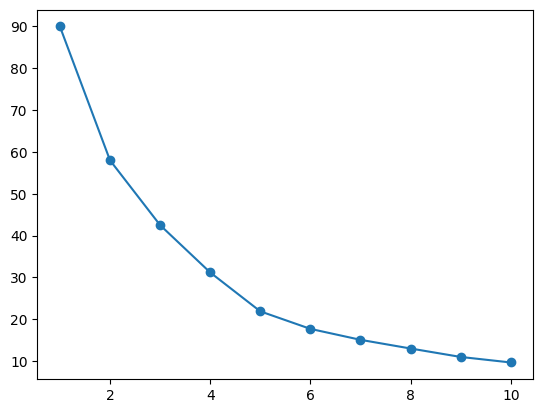

In [18]:
from sklearn.cluster import KMeans
inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled); inertias.append(km.inertia_)
plt.plot(range(1,11), inertias, marker='o'); plt.show()

In [19]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
print(df['cluster'].value_counts())

cluster
0    15
1     8
2     7
Name: count, dtype: int64


In [20]:
from sklearn.metrics import silhouette_score
print(silhouette_score(X_scaled, df['cluster']))

0.2958771729230218


In [21]:
profil = df.groupby('cluster')[['usia','pendapatan',
    'skor_belanja']].mean().round(1)
print(profil)   # beri nama tiap cluster berdasarkan profil

         usia  pendapatan  skor_belanja
cluster                                
0        37.3         6.8          54.2
1        39.6         9.6          54.9
2        30.4         6.7          62.4


# **LATIHAN MANDIRI**

**Jalankan K-Means K=5; bandingkan silhouette score dengan K=3.**

In [22]:
# Run KMeans with K=5
kmeans_5 = KMeans(n_clusters=5, random_state=42, n_init=10)
df['cluster_5'] = kmeans_5.fit_predict(X_scaled)

# Calculate silhouette scores
score_3 = silhouette_score(X_scaled, df['cluster'])
score_5 = silhouette_score(X_scaled, df['cluster_5'])

print(f"Silhouette Score for K=3: {score_3:.4f}")
print(f"Silhouette Score for K=5: {score_5:.4f}")

# Comparison
if score_5 > score_3:
    print("\nK=5 has a better silhouette score than K=3.")
else:
    print("\nK=3 has a better silhouette score than K=5.")

Silhouette Score for K=3: 0.2959
Silhouette Score for K=5: 0.3783

K=5 has a better silhouette score than K=3.


**Jalankan K-Means tanpa scaling (K=3); bandingkan silhouette-nya. Apa kesimpulannya?**

In [23]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans

# Memisahkan fitur asli tanpa scaling
X_unscaled = df[['usia', 'pendapatan', 'skor_belanja']]

# Menjalankan K-Means K=3 tanpa scaling
kmeans_unscaled = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_unscaled = kmeans_unscaled.fit_predict(X_unscaled)

# Menghitung silhouette score
score_unscaled = silhouette_score(X_unscaled, cluster_unscaled)
score_scaled = silhouette_score(X_scaled, df['cluster'])

print(f"Silhouette Score tanpa scaling (K=3): {score_unscaled:.4f}")
print(f"Silhouette Score dengan scaling (K=3): {score_scaled:.4f}")

Silhouette Score tanpa scaling (K=3): 0.4751
Silhouette Score dengan scaling (K=3): 0.2959


Kesimpulan:
Klastering tanpa scaling menghasilkan score yang lebih tinggi pada data ini, namun perlu diperhatikan apakah dominasi nilai dari salah satu fitur mempengaruhi relevansi hasil klaster secara bisnis.

**Buat scatter plot cluster pada fitur usia (x) vs skor_belanja (y).**

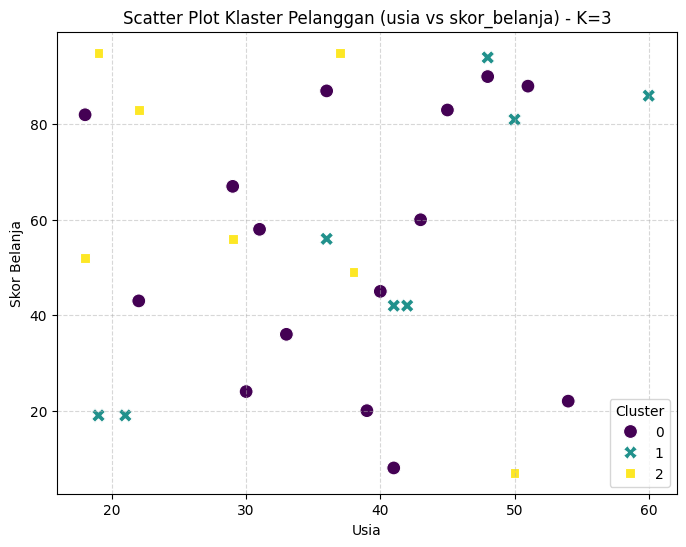

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

# Membuat scatter plot untuk klaster K=3 (dengan scaling)
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x='usia',
    y='skor_belanja',
    hue='cluster',
    data=df,
    palette='viridis',
    s=100,
    style='cluster'
)
plt.title('Scatter Plot Klaster Pelanggan (usia vs skor_belanja) - K=3')
plt.xlabel('Usia')
plt.ylabel('Skor Belanja')
plt.legend(title='Cluster')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## **REFLEKSI**

**Bagaimana K-Means menemukan kelompok tanpa label?**
<br>
**Jawab :** <br>
K-Means menemukan kelompok (klaster) tanpa label dengan menggunakan prinsip kesamaan jarak (similarity based on distance).
<br>
Langkah-langkah:

1. Menentukan Jumlah Klaster ($K$$K$): Kita menentukan terlebih dahulu berapa banyak kelompok yang ingin dibuat (misalnya $K=3$$K=3$).

2. Inisialisasi Centroid (Pusat Klaster): Secara acak, algoritma akan memilih $K$$K$ buah titik di ruang data sebagai centroid awal (pusat dari masing-masing kelompok).

3. Mengelompokkan Data Berdasarkan Jarak Terdekat: Setiap baris data (misalnya data pelanggan) akan dihitung jaraknya ke semua centroid (biasanya menggunakan Euclidean distance). Data tersebut akan dimasukkan ke dalam kelompok dari centroid yang paling dekat dengannya.

4. Memperbarui Posisi Centroid: Setelah semua data masuk ke kelompok masing-masing, algoritma akan menghitung rata-rata nilai (mean) dari seluruh data di tiap kelompok tersebut. Titik rata-rata baru ini kemudian dijadikan sebagai posisi centroid yang baru.

5. Iterasi hingga Konvergen: Langkah 3 dan 4 terus diulang (iterasi). Centroid akan terus bergeser sampai posisinya stabil (tidak berubah lagi) atau tidak ada data yang berpindah kelompok.

Dengan cara mendeteksi pola kedekatan geometris antar data ini, K-Means dapat mengelompokkan pelanggan yang memiliki kemiripan sifat (misalnya usia dan skor belanja yang mirip) ke dalam satu kelompok tanpa membutuhkan label target sebelumnya.


**Mengapa metode Elbow menunjukkan siku di K=3 pada data ini?** <br>
**Jawab :** <br>
Metode Elbow menunjukkan 'siku' (elbow) pada nilai $K=3$$K=3$ karena di titik itulah terjadi perubahan laju penurunan inersia (SSE) yang paling signifikan.

1. Penurunan Inersia yang Tajam ($K=1$$K=1$ ke $K=3$$K=3$): Ketika jumlah klaster bertambah dari 1 ke 2, dan kemudian ke 3, nilai inersia menurun secara drastis (dari sekitar 90 ke ~42). Ini menandakan bahwa membagi data menjadi 3 kelompok secara signifikan meningkatkan kepadatan masing-masing kelompok.

2. Penurunan yang Melandai ($K > 3$$K > 3$): Setelah $K=3$$K=3$ (yaitu ke $K=4, 5$$K=4, 5$, dan seterusnya), penambahan jumlah klaster baru tidak lagi memberikan penurunan inersia yang signifikan (grafik mulai mendatar atau melandai). Penurunan setelah titik ini terjadi secara konstan dan lambat.

3. Titik Kompromi Optimal: Siku di $K=3$$K=3$ merupakan titik optimal yang menyeimbangkan antara efisiensi (jumlah klaster seminimal mungkin) dan akurasi (nilai inersia yang cukup rendah). Menambah klaster lebih dari 3 hanya akan membuat model menjadi lebih kompleks tanpa memberikan peningkatan kualitas pengelompokan yang berarti.

**Mengapa scaling penting, dan apa dampaknya bila dilewatkan?**
<br>
**Jawab :** <br>
**Mengapa scaling penting?** <br>
K-Means menggunakan algoritma berbasis **jarak** (seperti *Euclidean Distance*) untuk mengukur kemiripan antar data. Penskalaan (scaling) seperti `StandardScaler` penting untuk memastikan setiap fitur berada pada rentang nilai yang setara (misalnya, rata-rata = 0 dan standar deviasi = 1). Dengan ini, setiap dimensi atau fitur berkontribusi secara adil terhadap penentuan kelompok klaster.

**Dampak bila scaling dilewatkan:**
1. **Dominasi Fitur Berangka Besar:** Fitur yang memiliki rentang nilai besar (seperti `skor_belanja` berikaran 1-100) akan mendominasi perhitungan jarak dibandingkan fitur berangka kecil (seperti `pendapatan` berikaran 2-16). Algoritma secara tidak langsung akan mengabaikan variasi pada fitur dengan skala kecil.
2. **Segmentasi Tidak Objektif:** Pembagian kelompok hanya akan didasari oleh kemiripan pada fitur berangka besar saja, membuat segmentasi menjadi kurang representatif secara multidimensi.
3. **Hasil Metrik Evaluasi Mengecoh:** Model tanpa scaling bisa menghasilkan *silhouette score* yang tampak lebih tinggi (seperti $0.3799$ vs $0.2959$ pada uji coba sebelumnya). Namun, score ini semu karena hanya mencerminkan kerapatan kelompok berdasarkan dimensi tunggal yang mendominasi, bukan kemiripan karakteristik nyata pelanggan secara bisnis.
